# Python para finanças - Taxas de Retorno Simples e Logarítmica

## Importação das bibliotecas e base de dados

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px  ### para gerar gráficos dinâmicos ###

In [2]:
dataset = pd.read_csv('/home/mgabriel4/Documentos/GitHub/python-investimentos/bases/acoes_ex.csv', index_col=0, parse_dates=True)

In [3]:
dataset.shape

(1446, 6)

In [4]:
dataset.round(2)

,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
Date,,,,,,
2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26
2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32
2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58
2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15
2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51
...,...,...,...,...,...,...
2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80
2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43
2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91


In [5]:
dataset['Date'] = pd.to_datetime(dataset['Date'])

####converte os valores da coluna Date para o tipo datetime64, que é o formato de data/hora do pandas,
 ####tenho q fazer isso poois o pandas não sabe q é um data ele trata como texto ####


KeyError: 'Date'

In [ ]:
resultado_fevereiro = dataset[(dataset['Date'].dt.year == 2019) & (dataset['Date'].dt.month == 2)]

resultado_fevereiro.round(2)

### .dt é o acessador de datas e horários do pandas. Ele permite pegar partes de uma coluna de datas: ####
### - dataset['Date'].dt.year → ano   ####
### - dataset['Date'].dt.month → mês  ####



,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
1015,2019-02-01,24.92,64.80,19.63,5.59,33.09,94.36
1016,2019-02-04,26.98,63.85,19.70,5.53,33.34,95.03
1017,2019-02-05,27.59,62.85,20.05,5.48,34.36,94.80
1018,2019-02-06,26.79,60.00,19.34,5.30,33.66,91.27
1019,2019-02-07,26.36,60.73,19.17,5.21,32.66,91.00
1020,2019-02-08,27.03,61.00,19.00,5.31,32.24,91.70
1021,2019-02-11,27.82,61.16,18.89,5.17,32.32,90.99
1022,2019-02-12,28.54,63.24,18.87,5.15,31.43,92.45
1023,2019-02-13,28.65,62.37,18.66,5.04,31.74,92.60
1024,2019-02-14,28.50,63.00,18.84,5.33,32.52,94.34


In [ ]:
dataset['Date'] = pd.to_datetime(dataset['Date'])
resultado_2020 = dataset[dataset['Date'].dt.year == 2020]

resultado_2020.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
1241,2020-01-02,37.17,44.71,35.24,12.33,69.15,114.24
1242,2020-01-03,35.90,44.20,34.79,12.22,70.62,113.80
1243,2020-01-06,34.25,43.82,34.88,12.23,69.01,112.59
1244,2020-01-07,34.45,44.40,35.15,12.20,69.30,112.24
1245,2020-01-08,35.81,44.34,33.82,12.57,68.37,111.95
...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66


# Taxa de retorno simples (pode sofrer distorções para valores grandes e é utilizada na prática)

In [ ]:
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66


In [ ]:
len(dataset)

1446

In [ ]:
dataset['GOL'][0], dataset['GOL'][len(dataset) - 1]

### pegamos o primeiro valor e o último valor ####

(np.float64(14.989999771118164), np.float64(16.06999969482422))

In [ ]:
taxa_retorno_simples_gol = ((dataset['GOL'][len(dataset) - 1] - dataset['GOL'][0]) / dataset['GOL'][0]) * 100

print(f'A taxa de retorno simples da GOL é {taxa_retorno_simples_gol:.2f}%')

#### pegamos o último valor e dividimos pelo primeiro, então nesse período ####
#### as ações da gol desvalorizou em cerca de 7,2% #######

A taxa de retorno simples da GOL é 7.20%


In [ ]:
taxa_retorno_simples_cvc = ((dataset['CVC'][len(dataset) - 1] - dataset['CVC'][0]) / dataset['CVC'][0]) * 100

print(f'A taxa de retorno simples da CVC é {taxa_retorno_simples_cvc:.2f}%')

A taxa de retorno simples da CVC é -18.29%


In [ ]:
taxa_retorno_simples_weg = ((dataset['WEGE'][len(dataset) - 1] - dataset['WEGE'][0]) / dataset['WEGE'][0]) * 100

print(f'A taxa de retorno simples da WEG é {taxa_retorno_simples_weg:.2f}%')

A taxa de retorno simples da WEG é 564.09%


In [ ]:
taxa_retorno_simples_mglu = ((dataset['MGLU'][len(dataset) - 1] - dataset['MGLU'][0]) / dataset['MGLU'][0]) * 100

print(f'A taxa de retorno simples da MAGALU é {taxa_retorno_simples_mglu:.2f}%')

A taxa de retorno simples da MAGALU é 10771.43%


In [ ]:
taxa_retorno_simples_tots = ((dataset['TOTS'][len(dataset) - 1] - dataset['TOTS'][0]) / dataset['TOTS'][0]) * 100

print(f'A taxa de retorno simples da TOVS é {taxa_retorno_simples_tots:.2f}%')

A taxa de retorno simples da TOVS é -21.83%


In [ ]:
taxa_retorno_simples_bova = ((dataset['BOVA'][len(dataset) - 1] - dataset['BOVA'][0]) / dataset['BOVA'][0]) * 100

print(f'A taxa de retorno simples da BOVA é {taxa_retorno_simples_bova:.2f}%')

A taxa de retorno simples da BOVA é 95.54%


In [ ]:
taxa_outra_forma__retorno_simples_bova = (dataset['BOVA'][len(dataset) - 1] / dataset['BOVA'][0] - 1) * 100
### outra forma de calcular RS = (preço final/preço inicial -1)*100

print(f'A taxa de retorno simples da BOVA é {taxa_outra_forma__retorno_simples_bova:.2f}%')

A taxa de retorno simples da BOVA é 95.54%


## TAXA DE RETORNO DIÁRIA

In [ ]:
dataset['GOL'].round(2)  ### ações da gol #####

,GOL
0,14.99
1,14.85
2,15.21
3,14.55
4,14.27
...,...
1441,18.60
1442,16.92
1443,16.61
1444,15.69


O comando .shift() do pandas é usado para deslocar os dados de uma série ou coluna de um DataFrame para cima ou para baixo.

shift(n)

n é o número de posições a deslocar:

n > 0: desloca para baixo (valores passados).

n < 0: desloca para cima (valores futuros).

n = 0: não faz nada.

In [ ]:
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66


In [ ]:
dataset['GOL'].round(2)

,GOL
0,14.99
1,14.85
2,15.21
3,14.55
4,14.27
...,...
1441,18.60
1442,16.92
1443,16.61
1444,15.69


In [ ]:
dataset['GOL'].shift(1)

### Ele desloca os valores da coluna para baixo em n posições. ###

###  Os primeiros n elementos ficam como NaN (valores ausentes), porque não há dados anteriores para preenchê-los.###

,GOL
0,NaN
1,14.990000
2,14.850000
3,15.210000
4,14.550000
...,...
1441,18.959999
1442,18.600000
1443,16.920000
1444,16.610001


* dataset['GOL'] → preços da ação GOL no dia atual.

* dataset['GOL'].shift(1) → preços da GOL do dia anterior (deslocados 1 linha para baixo).

Divisão → preço de hoje ÷ preço de ontem.

 * - 1 → transforma essa razão em taxa de variação percentual.

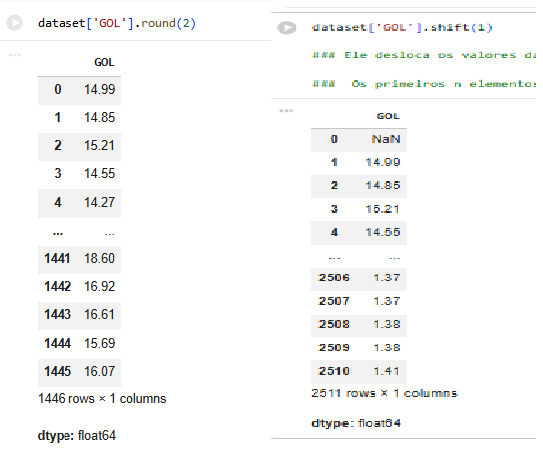

In [ ]:
dataset['RS GOL'] = (dataset['GOL'] / dataset['GOL'].shift(1)) - 1

In [ ]:
dataset['RS GOL'].round(2)

,RS GOL
0,NaN
1,-0.01
2,0.02
3,-0.04
4,-0.02
...,...
1441,-0.02
1442,-0.09
1443,-0.02
1444,-0.06


In [ ]:
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,RS GOL
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26,NaN
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32,-0.01
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58,0.02
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15,-0.04
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51,-0.02
...,...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80,-0.02
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43,-0.09
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91,-0.02
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66,-0.06


In [ ]:
fig = px.line(dataset, y='RS GOL', title='Taxa de Retornos Diários da GOL')
fig.show()

In [ ]:
media_dos_retornos_simples_da_GOL = dataset['RS GOL'].mean()


print(f'A média dos retornos simples da GOL é {media_dos_retornos_simples_da_GOL:.3f} reais')



A média dos retornos simples da GOL é 0.001 reais


## TAXA DE RETORNO MÉDIO ANUAL

In [ ]:
dataset.head(246).round(2)
 ### 246 é a média q a bolsa brasileira fica aberta ####

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,RS GOL
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26,NaN
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32,-0.01
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58,0.02
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15,-0.04
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51,-0.02
...,...,...,...,...,...,...,...,...
241,2015-12-22,2.49,12.35,11.90,0.04,30.94,42.23,-0.11
242,2015-12-23,2.46,12.48,11.96,0.05,31.94,42.75,-0.01
243,2015-12-28,2.39,12.45,12.12,0.06,31.29,42.50,-0.03
244,2015-12-29,2.39,13.10,11.98,0.07,31.29,42.42,0.00


In [ ]:
dataset.tail(246).round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,RS GOL
1200,2019-10-29,38.26,52.00,25.52,10.29,62.00,103.50,0.02
1201,2019-10-30,38.85,51.50,25.85,11.01,63.25,104.29,0.02
1202,2019-10-31,36.60,51.23,25.50,11.16,62.28,103.23,-0.06
1203,2019-11-01,36.40,53.05,25.88,11.80,63.31,104.27,-0.01
1204,2019-11-04,35.61,52.39,26.13,11.24,61.93,104.63,-0.02
...,...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80,-0.02
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43,-0.09
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91,-0.02
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66,-0.06


In [ ]:
(dataset['RS GOL'].mean() * 246) * 100

 ### calcula a média do retorno diário da GOL #####

np.float64(33.23897823054538)

In [ ]:
dataset['RS CVC'] = (dataset['CVC'] / dataset['CVC'].shift(1)) - 1
dataset['RS WEGE'] = (dataset['WEGE'] / dataset['WEGE'].shift(1)) - 1
dataset['RS MGLU'] = (dataset['MGLU'] / dataset['MGLU'].shift(1)) - 1
dataset['RS TOTS'] = (dataset['TOTS'] / dataset['TOTS'].shift(1)) - 1
dataset['RS BOVA'] = (dataset['BOVA'] / dataset['BOVA'].shift(1)) - 1

In [ ]:
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,RS GOL,RS CVC,RS WEGE,RS MGLU,RS TOTS,RS BOVA
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32,-0.01,-0.01,0.01,0.02,-0.03,-0.02
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58,0.02,-0.01,-0.01,-0.01,-0.06,0.01
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15,-0.04,-0.01,-0.01,0.03,-0.01,0.03
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51,-0.02,-0.04,0.02,-0.01,0.02,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80,-0.02,-0.02,0.01,-0.00,0.01,-0.01
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43,-0.09,-0.10,-0.05,-0.03,-0.04,-0.04
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91,-0.02,-0.01,0.01,0.03,0.04,0.01
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66,-0.06,-0.03,-0.05,-0.03,-0.05,-0.02


In [ ]:
(dataset['RS CVC'].mean() * 246) * 100

np.float64(11.87607869173827)

In [ ]:
(dataset['RS WEGE'].mean() * 246) * 100

np.float64(38.35190660073094)

In [ ]:
(dataset['RS MGLU'].mean() * 246) * 100

np.float64(101.2429849201322)

In [ ]:
(dataset['RS TOTS'].mean() * 246) * 100

np.float64(10.43406825404327)

In [ ]:
(dataset['RS BOVA'].mean() * 246) * 100

np.float64(15.133989484068467)

# Taxa de retorno logarítmica (mais estável não sofre distorções para valores grandes e é utilizada em cálculos estatísticos)

In [ ]:
dataset['GOL'][0], dataset['GOL'][len(dataset) - 1]

(np.float64(14.989999771118164), np.float64(16.06999969482422))

In [ ]:
taxa_retorno_log_gol = np.log(dataset['GOL'][len(dataset) - 1] / dataset['GOL'][0]) * 100
print(f'A taxa de retorno logarítmica da Gol é: {taxa_retorno_log_gol:.2f}%')

A taxa de retorno logarítmica da Gol é: 6.96%


In [ ]:
taxa_retorno_log_cvc = np.log(dataset['CVC'][len(dataset) - 1] / dataset['CVC'][0]) * 100
print(f'A taxa de retorno logarítmica da CVC é: {taxa_retorno_log_cvc:.2f}%')

A taxa de retorno logarítmica da CVC é: -20.20%


In [ ]:
taxa_retorno_log_weg = np.log(dataset['WEGE'][len(dataset) - 1] / dataset['WEGE'][0]) * 100
print(f'A taxa de retorno logarítmica da WEGE é: {taxa_retorno_log_weg:.2f}%')

A taxa de retorno logarítmica da WEGE é: 189.33%


In [ ]:
taxa_retorno_log_mglu = np.log(dataset['MGLU'][len(dataset) - 1] / dataset['MGLU'][0]) * 100
print(f'A taxa de retorno logarítmica da MGLU é: {taxa_retorno_log_mglu:.2f}%')

A taxa de retorno logarítmica da MGLU é: 468.87%


In [ ]:
taxa_retorno_log_tots = np.log(dataset['TOTS'][len(dataset) - 1] / dataset['TOTS'][0]) * 100
print(f'A taxa de retorno logarítmica da TOTS é: {taxa_retorno_log_tots:.2f}%')

A taxa de retorno logarítmica da TOTS é: -24.63%


In [ ]:
taxa_retorno_log_bova = np.log(dataset['BOVA'][len(dataset) - 1] / dataset['BOVA'][0]) * 100
print(f'A taxa de retorno logarítmica da Bova é: {taxa_retorno_log_bova:.2f}%')

A taxa de retorno logarítmica da Bova é: 67.06%


In [ ]:
dataset['RL GOL'] = np.log(dataset['GOL'] / dataset['GOL'].shift(1))
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,RL GOL
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26,NaN
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32,-0.01
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58,0.02
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15,-0.04
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51,-0.02
...,...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80,-0.02
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43,-0.09
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91,-0.02
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66,-0.06


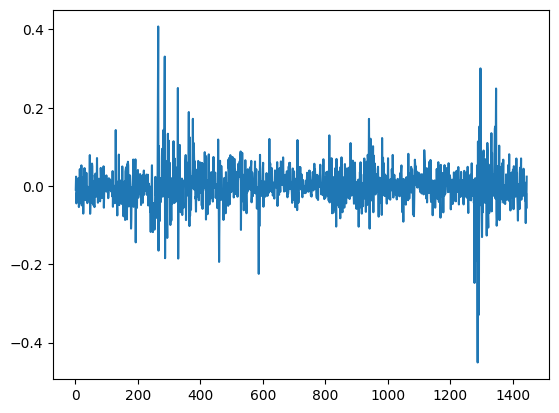

In [ ]:
dataset['RL GOL'].plot();

In [ ]:
dataset['RL GOL'].mean()

np.float64(4.814592658372141e-05)

In [ ]:
(dataset['RL GOL'].mean() * 246) * 100

np.float64(1.184389793959547)

In [ ]:
dataset['RL CVC'] = np.log(dataset['CVC'] / dataset['CVC'].shift(1))
dataset['RL WEGE'] = np.log(dataset['WEGE'] / dataset['WEGE'].shift(1))
dataset['RL MGLU'] = np.log(dataset['MGLU'] / dataset['MGLU'].shift(1))
dataset['RL TOTS'] = np.log(dataset['TOTS'] / dataset['TOTS'].shift(1))
dataset['RL BOVA'] = np.log(dataset['BOVA'] / dataset['BOVA'].shift(1))

In [ ]:
dataset.head().round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,RL GOL,RL CVC,RL WEGE,RL MGLU,RL TOTS,RL BOVA
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32,-0.01,-0.01,0.01,0.02,-0.03,-0.02
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58,0.02,-0.01,-0.01,-0.01,-0.06,0.01
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15,-0.04,-0.01,-0.01,0.03,-0.01,0.03
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51,-0.02,-0.04,0.02,-0.01,0.02,0.01


In [ ]:
(dataset['RL CVC'].mean() * 246) * 100

np.float64(-3.4386770818897774)

In [ ]:
(dataset['RL WEGE'].mean() * 246) * 100

np.float64(32.23118770450794)

In [ ]:
(dataset['RL MGLU'].mean() * 246) * 100

np.float64(79.82186824649435)

In [ ]:
(dataset['RL TOTS'].mean() * 246) * 100

np.float64(-4.1938845047394135)

In [ ]:
(dataset['RL BOVA'].mean() * 246) * 100

np.float64(11.415949226040405)

# Retorno de carteira de ações

In [ ]:
dataset = pd.read_csv('acoes.csv')
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66


In [ ]:
dataset_normalizado = dataset.copy()
for i in dataset_normalizado.columns[1:]:
  dataset_normalizado[i] = (dataset_normalizado[i] / dataset_normalizado[i][0])

In [ ]:
dataset_normalizado.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,2015-01-02,1.00,1.00,1.00,1.00,1.00,1.00
1,2015-01-05,0.99,0.99,1.01,1.02,0.97,0.98
2,2015-01-06,1.01,0.97,0.99,1.01,0.91,0.99
3,2015-01-07,0.97,0.97,0.98,1.04,0.90,1.02
4,2015-01-08,0.95,0.93,1.00,1.03,0.92,1.03
...,...,...,...,...,...,...,...
1441,2020-10-27,1.24,0.93,7.03,109.32,0.80,2.03
1442,2020-10-28,1.13,0.84,6.68,105.79,0.77,1.96
1443,2020-10-29,1.11,0.83,6.76,108.93,0.80,1.97
1444,2020-10-30,1.05,0.81,6.40,105.79,0.76,1.92


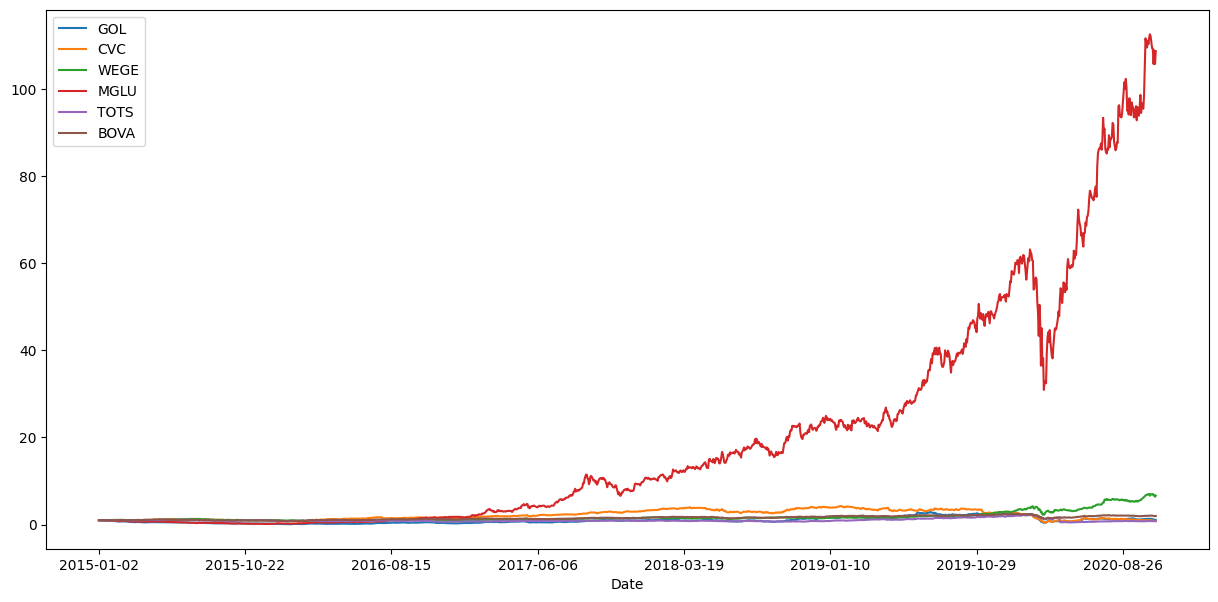

In [ ]:
dataset_normalizado.plot(x = 'Date', figsize=(15, 7));

In [ ]:
dataset_normalizado.drop(labels=['Date'], axis=1, inplace=True)

In [ ]:
retorno_carteira = (dataset_normalizado / dataset_normalizado.shift(1)) - 1
retorno_carteira.head().round(2)
### foram calculados os retornos diários de cada ativo, ###
### dividindo o valor do dia pelo valor do dia anterior e subtraindo 1 ###

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.01,-0.01,0.01,0.02,-0.03,-0.02
2,0.02,-0.01,-0.01,-0.01,-0.06,0.01
3,-0.04,-0.01,-0.01,0.03,-0.01,0.03
4,-0.02,-0.04,0.02,-0.01,0.02,0.01


In [ ]:
retorno_anual = retorno_carteira.mean() * 246
retorno_anual.round(2)
###os retornos foram usados para calcular o retorno médio anualizado ###

,0
GOL,0.33
CVC,0.12
WEGE,0.38
MGLU,1.01
TOTS,0.10
BOVA,0.15


In [ ]:
retorno_anual = retorno_anual * 100
retorno_anual.round(2)

,0
GOL,33.24
CVC,11.88
WEGE,38.35
MGLU,101.24
TOTS,10.43
BOVA,15.13


In [ ]:
pesos_carteira1 = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0])

In [ ]:
pesos_carteira1.sum()

np.float64(1.0)

In [ ]:
retorno_medio_anualizado_1 = np.dot(retorno_anual, pesos_carteira1)
print(f'O retorno médio anualizado da carteira é: {retorno_medio_anualizado_1:.2f}%')

O retorno médio anualizado da carteira é: 39.03%


In [ ]:
pesos_carteira2 = np.array([0.1, 0.2, 0.2, 0.4, 0.1, 0.0])

In [ ]:
pesos_carteira2.sum()

np.float64(1.0)

In [ ]:
retorno_medio_anualizado_2 = np.dot(retorno_anual, pesos_carteira2)
print(f'O retorno médio anualizado da carteira é: {retorno_medio_anualizado_2:.2f}%')

O retorno médio anualizado da carteira é: 54.91%


## Gráfico da carteira x BOVA

In [ ]:
dataset = pd.read_csv('acoes.csv')
dataset.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,2015-01-02,14.99,15.20,11.85,0.23,35.73,47.26
1,2015-01-05,14.85,15.00,11.93,0.24,34.63,46.32
2,2015-01-06,15.21,14.80,11.75,0.23,32.47,46.58
3,2015-01-07,14.55,14.67,11.62,0.24,32.24,48.15
4,2015-01-08,14.27,14.15,11.81,0.24,32.99,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,18.60,14.17,83.24,25.45,28.50,95.80
1442,2020-10-28,16.92,12.77,79.14,24.63,27.50,92.43
1443,2020-10-29,16.61,12.68,80.03,25.36,28.50,92.91
1444,2020-10-30,15.69,12.28,75.83,24.63,27.00,90.66


In [ ]:
dataset['Date'] = pd.to_datetime(dataset['Date'])
### transforma a coluna Date em data ###

In [ ]:
dataset_normalizado = dataset.copy()
for i in dataset_normalizado.columns[1:]:
  dataset_normalizado[i] = (dataset_normalizado[i] / dataset_normalizado[i][0])
dataset_normalizado.head().round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA
0,2015-01-02,1.00,1.00,1.00,1.00,1.00,1.00
1,2015-01-05,0.99,0.99,1.01,1.02,0.97,0.98
2,2015-01-06,1.01,0.97,0.99,1.01,0.91,0.99
3,2015-01-07,0.97,0.97,0.98,1.04,0.90,1.02
4,2015-01-08,0.95,0.93,1.00,1.03,0.92,1.03


In [ ]:
dataset_normalizado['CARTEIRA'] = (dataset_normalizado['GOL'] + dataset_normalizado['CVC'] + dataset_normalizado['WEGE'] + dataset_normalizado['MGLU'] + dataset_normalizado['TOTS']) / 5
dataset_normalizado.round(2)

,Date,GOL,CVC,WEGE,MGLU,TOTS,BOVA,CARTEIRA
0,2015-01-02,1.00,1.00,1.00,1.00,1.00,1.00,1.00
1,2015-01-05,0.99,0.99,1.01,1.02,0.97,0.98,0.99
2,2015-01-06,1.01,0.97,0.99,1.01,0.91,0.99,0.98
3,2015-01-07,0.97,0.97,0.98,1.04,0.90,1.02,0.97
4,2015-01-08,0.95,0.93,1.00,1.03,0.92,1.03,0.97
...,...,...,...,...,...,...,...,...
1441,2020-10-27,1.24,0.93,7.03,109.32,0.80,2.03,23.86
1442,2020-10-28,1.13,0.84,6.68,105.79,0.77,1.96,23.04
1443,2020-10-29,1.11,0.83,6.76,108.93,0.80,1.97,23.68
1444,2020-10-30,1.05,0.81,6.40,105.79,0.76,1.92,22.96


In [ ]:
figura = px.line(title = 'Comparativo carteira x BOVA')
for i in dataset_normalizado.columns[1:]:
  figura.add_scatter(x = dataset_normalizado['Date'], y = dataset_normalizado[i], name = i)
figura.show()

In [ ]:
dataset_normalizado.drop(['GOL', 'WEGE', 'CVC', 'MGLU', 'TOTS'], axis = 1, inplace= True, errors='ignore')
dataset_normalizado.round(2)

,Date,BOVA,CARTEIRA
0,2015-01-02,1.00,1.00
1,2015-01-05,0.98,0.99
2,2015-01-06,0.99,0.98
3,2015-01-07,1.02,0.97
4,2015-01-08,1.03,0.97
...,...,...,...
1441,2020-10-27,2.03,23.86
1442,2020-10-28,1.96,23.04
1443,2020-10-29,1.97,23.68
1444,2020-10-30,1.92,22.96


In [ ]:
figura = px.line(title = 'Comparativo carteira x BOVA')
for i in dataset_normalizado.columns[1:]:
  figura.add_scatter(x = dataset_normalizado['Date'], y = dataset_normalizado[i], name = i)
figura.show()

## Exercício

### Taxa de retorno da carteira

In [ ]:
dataset1 = pd.read_csv('acoes_ex.csv')
dataset1

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.020000,9.37,37.820000,9.000000,22.650000,47.259998
1,2015-01-05,15.730000,9.62,37.070000,8.270000,22.180000,46.320000
2,2015-01-06,16.330000,9.55,36.150002,8.060000,22.490000,46.580002
3,2015-01-07,16.559999,9.69,37.389999,8.450000,23.480000,48.150002
4,2015-01-08,16.540001,9.66,38.910000,9.020000,23.559999,48.509998
...,...,...,...,...,...,...,...
1441,2020-10-27,13.720000,14.00,43.480000,19.860001,32.779999,95.800003
1442,2020-10-28,13.370000,12.97,42.610001,18.639999,31.139999,92.430000
1443,2020-10-29,12.890000,12.84,42.250000,19.330000,30.959999,92.910004
1444,2020-10-30,12.180000,12.61,42.669998,19.000000,29.799999,90.660004


In [ ]:
acoes_df_normalizado = dataset1.copy()
for i in acoes_df_normalizado.columns[1:]:
  acoes_df_normalizado[i] = (acoes_df_normalizado[i] / acoes_df_normalizado[i][0])

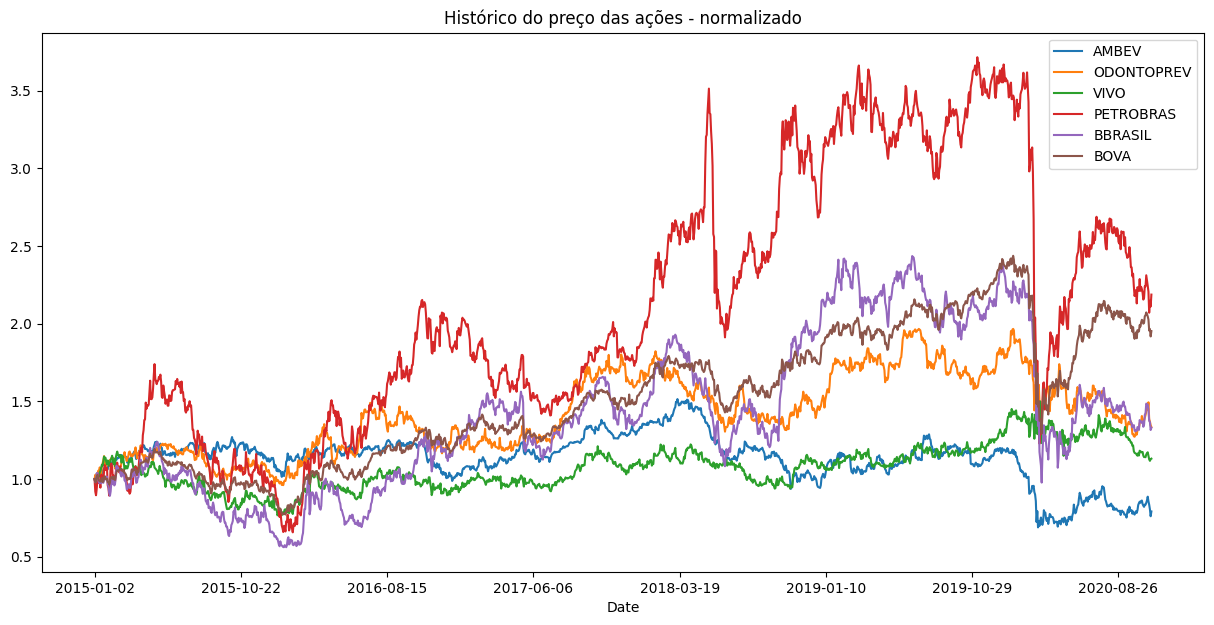

In [ ]:
acoes_df_normalizado.plot(x = 'Date', figsize = (15,7), title = 'Histórico do preço das ações - normalizado');

In [ ]:
acoes_df_normalizado.drop(labels = ['Date'], axis = 1, inplace = True)

In [ ]:
retorno_carteira = (acoes_df_normalizado / acoes_df_normalizado.shift(1)) - 1
retorno_carteira.head()

,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.018102,0.026681,-0.019831,-0.081111,-0.020751,-0.019890
2,0.038144,-0.007276,-0.024818,-0.025393,0.013977,0.005613
3,0.014084,0.014660,0.034301,0.048387,0.044020,0.033705
4,-0.001208,-0.003096,0.040653,0.067456,0.003407,0.007477


In [ ]:
retorno_anual = retorno_carteira.mean() * 246
retorno_anual

,0
AMBEV,-0.003055
ODONTOPREV,0.098360
VIVO,0.071963
PETROBRAS,0.276396
BBRASIL,0.159670
BOVA,0.151077


In [ ]:
retorno_anual = retorno_anual * 100
retorno_anual

,0
AMBEV,-0.305458
ODONTOPREV,9.835984
VIVO,7.196278
PETROBRAS,27.639591
BBRASIL,15.967003
BOVA,15.107699


In [ ]:
pesos_carteira = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0])

In [ ]:
np.dot(retorno_anual, pesos_carteira)

np.float64(12.066679602082445)

### Gráfico carteira x BOVA

In [ ]:
dataset1 = pd.read_csv('acoes_ex.csv')

In [ ]:
acoes_df_normalizado = dataset1.copy()
for i in acoes_df_normalizado.columns[1:]:
  acoes_df_normalizado[i] = (acoes_df_normalizado[i] / acoes_df_normalizado[i][0])

In [ ]:
dataset1.columns

Index(['Date', 'AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL', 'BOVA'], dtype='object')

In [ ]:
acoes_df_normalizado['CARTEIRA'] = (acoes_df_normalizado['AMBEV'] + acoes_df_normalizado['ODONTOPREV'] + acoes_df_normalizado['VIVO'] + acoes_df_normalizado['PETROBRAS'] + acoes_df_normalizado['BBRASIL']) / 5
acoes_df_normalizado

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110,0.977377
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612,0.976579
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832,1.006405
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449,1.026926
...,...,...,...,...,...,...,...,...
1441,2020-10-27,0.856429,1.494130,1.149656,2.206667,1.447241,2.027084,1.430825
1442,2020-10-28,0.834582,1.384205,1.126653,2.071111,1.374834,1.955777,1.358277
1443,2020-10-29,0.804619,1.370331,1.117134,2.147778,1.366887,1.965933,1.361350
1444,2020-10-30,0.760300,1.345784,1.128239,2.111111,1.315673,1.918324,1.332221


In [ ]:
figura = px.line(title = 'Histórico do preço das ações')
for i in acoes_df_normalizado.columns[1:]:
  figura.add_scatter(x = acoes_df_normalizado['Date'], y = acoes_df_normalizado[i], name = i)
figura.show()

In [ ]:
acoes_df_normalizado.drop(['AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL'], axis = 1, inplace = True)
acoes_df_normalizado

,Date,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000
1,2015-01-05,0.980110,0.977377
2,2015-01-06,0.985612,0.976579
3,2015-01-07,1.018832,1.006405
4,2015-01-08,1.026449,1.026926
...,...,...,...
1441,2020-10-27,2.027084,1.430825
1442,2020-10-28,1.955777,1.358277
1443,2020-10-29,1.965933,1.361350
1444,2020-10-30,1.918324,1.332221


In [ ]:
figura = px.line(title = 'Histórico do preço das ações')
for i in acoes_df_normalizado.columns[1:]:
  figura.add_scatter(x = acoes_df_normalizado['Date'], y = acoes_df_normalizado[i], name = i)
figura.show()